# Laboratorium 4 - klasyfikacja tekstur i reprezentacja falkowa

Realizacja A-E: oryginalny Kylberg, dwa rozmiary S1, małe CNN z augmentacją i dropout, trójpoziomowe S2 dla falek **Haar** i **db2**, a następnie wektory S3 **9D** oparte wyłącznie na energii detali.

Nie dostarczono rysunku ani wzoru z treści zadania. Z opisu przyjmujemy **średnią energię pasma E = mean(c²)**. Znaki współczynników nie znoszą się. Aproksymacja A3 jest zachowana w pełnym S2, ale **nie jest cechą S3**.

Źródła: [strona zbioru](https://user.it.uu.se/~gusky180/texture/), [serwer autora](https://filedn.com/lkCRue0RhPO7ercIrqFRl2Y/datasets/KylbergTextureDatasetV1/without-rotations-zip/), [dokumentacja PyWavelets](https://pywavelets.readthedocs.io/en/latest/ref/2d-dwt-and-idwt.html).

Pytanie badawcze: jak wyniki tego samego typu CNN oraz pomocniczego klasyfikatora na 9D zmieniają się po zwiększeniu liczby obrazów przy zachowaniu klas? Jeden przebieg nie dowodzi przewagi danej metody w ogólności.

## 0. Konfiguracja i odtwarzalność

Stałe klasy i ziarno ustalamy przed uczeniem. Model wybieramy według straty walidacyjnej; test nie wpływa na epokę ani parametry. `RETRAIN=False` wczytuje zgodne wagi i historię, jeżeli już istnieją. S2 zapisujemy raz dla większego zbioru; mniejszy wskazuje jego wiersze, zamiast duplikować współczynniki.

In [1]:
import copy
import csv
import hashlib
import json
import platform
import random
import re
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pywt
import torch
import torchvision
from PIL import Image
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

LAB = Path.cwd()
if (LAB / 'lab4').is_dir():
    LAB = LAB / 'lab4'
DATA = LAB / 'data' / 'kylberg'
OUT = LAB / 'wyniki_lab4'
OUT.mkdir(exist_ok=True)
(OUT / 'S2').mkdir(exist_ok=True)
CLASSES = ['blanket1', 'canvas1', 'cushion1', 'lentils1', 'rice1', 'stone1']
SEED = 2026
WAVELETS = ('haar', 'db2')
LEVELS = 3
DWT_MODE = 'periodization'
CNN_SIZE = 192
MAX_EPOCHS = 30
PATIENCE = 8
BATCH_SIZE = 32
RETRAIN = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def save_json(path, data):
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')


set_seed()
versions = {'python': platform.python_version(), 'numpy': np.__version__,
            'torch': torch.__version__, 'torchvision': torchvision.__version__,
            'PyWavelets': pywt.__version__}
print(versions)
print('Urządzenie:', device)
print('Katalog laboratorium:', LAB)

{'python': '3.12.0', 'numpy': '1.26.4', 'torch': '2.5.1+cu121', 'torchvision': '0.20.1+cu121', 'PyWavelets': '1.8.0'}
Urządzenie: cuda
Katalog laboratorium: C:\Users\mateu\Desktop\Studia\MRO\lab4


## A. Weryfikacja pobranego zbioru

Pobieramy pełne **28 × 160 = 4480** oryginalnych obrazów bez gotowych obrotów przez `pobierz_dane.py`. Na serwerze uniwersytetu katalog pełnego zbioru był pusty; skrypt korzysta z archiwów udostępnionych przez autora. Ich adresy, rozmiary i SHA-256 są zapisane w `data/download_manifest.json`.

Nie używamy małego ZIP-a 6 × 40 jako pełnego zbioru - nie wystarczyłby do znacznie większego wariantu. Kontrolujemy liczebności, unikalność nazw oraz rozmiar i tryb każdego PNG.

Zweryfikowano 4480 obrazów, 28 klas, 576 x 576, skala szarości.


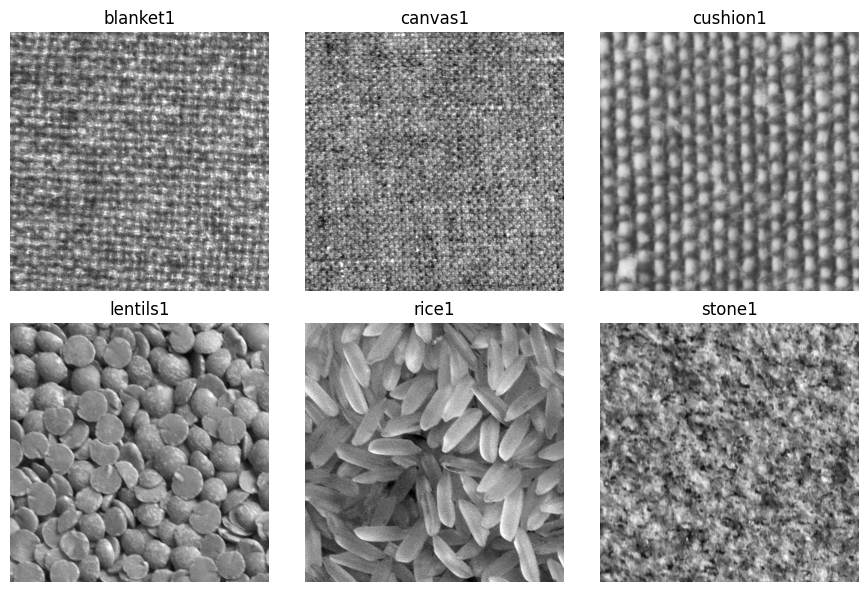

In [2]:
all_files = sorted(DATA.rglob('*.png'))
if not all_files:
    raise FileNotFoundError('Brak danych. Uruchom: python pobierz_dane.py')
pattern = re.compile(r'^(?P<class>.+)-(?P<source>[a-d])-p(?P<patch>\d+)(?:-r000)?\.png$')
all_records = []
for path in all_files:
    match = pattern.fullmatch(path.name)
    assert match, f'Nieoczekiwana nazwa lub gotowy obrót: {path.name}'
    with Image.open(path) as image:
        assert image.size == (576, 576) and image.mode == 'L', (path.name, image.size, image.mode)
    all_records.append({'path': path, 'class': match['class'], 'source': match['source']})
all_classes = sorted({r['class'] for r in all_records})
assert len(all_records) == 4480 and len(all_classes) == 28
assert len({p.name for p in all_files}) == 4480
for name in all_classes:
    assert sum(r['class'] == name for r in all_records) == 160
    for source in 'abcd':
        assert sum(r['class'] == name and r['source'] == source for r in all_records) == 40
print(f'Zweryfikowano {len(all_records)} obrazów, {len(all_classes)} klas, 576 x 576, skala szarości.')
records = [r for name in CLASSES for r in all_records if r['class'] == name]
y = np.array([CLASSES.index(r['class']) for r in records], dtype=np.int64)
filenames = np.array([r['path'].name for r in records])
signature_text = '\n'.join(f'{r["path"].name}:{r["path"].stat().st_size}' for r in records)
data_signature = hashlib.sha256(signature_text.encode()).hexdigest()
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for ax, name in zip(axes.flat, CLASSES):
    path = next(r['path'] for r in records if r['class'] == name)
    with Image.open(path) as image:
        ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    ax.set_title(name)
    ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'przyklady_klas.png', dpi=170, bbox_inches='tight')
plt.show()

## B i E. Mały oraz znacznie większy podzbiór S1

**Te same 6 klas:** blanket1, canvas1, cushion1, lentils1, rice1, stone1.

| Wariant | Na klasę | Trening | Walidacja | Test w S1 | Razem |
|---|---:|---:|---:|---:|---:|
| Mały | 40 | 20 | 10 | 10 | 240 |
| Duży | 160 | 80 | 40 | 40 | 960 |

Liczebności trening/walidacja/test w tabeli podano **na klasę**. Mały zbiór jest zagnieżdżony w dużym. W każdej klasie fotografie źródłowe **a,b** trafiają wyłącznie do treningu, **c** do walidacji, **d** do testu. Zapobiega to przeciekowi między fragmentami tej samej fotografii. Augmentacja odbywa się dopiero po podziale.

Oba modele ocenimy na **tych samych 240 obrazach testowych** z fotografii d (pełny test dużego S1); również na wspólnych 60 z małego S1. Dodatkowe obrazy testowe nie uczą małego modelu. Walidacje mają różne liczebności, więc wynik nie jest kontrolowanym pomiarem wpływu wyłącznie liczby obrazów treningowych.

In [3]:
rng = np.random.default_rng(SEED)
parts = {size: {split: [] for split in ('train', 'val', 'test')}
         for size in ('maly', 'duzy')}
for label in range(len(CLASSES)):
    source_ids = {}
    for source in 'abcd':
        ids = np.array([i for i, r in enumerate(records)
                        if y[i] == label and r['source'] == source], dtype=np.int64)
        source_ids[source] = rng.permutation(ids)
    train_large = np.concatenate([source_ids['a'], source_ids['b']])
    train_small = np.concatenate([source_ids['a'][:10], source_ids['b'][:10]])
    for size, splits in [('maly', (train_small, source_ids['c'][:10], source_ids['d'][:10])),
                         ('duzy', (train_large, source_ids['c'], source_ids['d']))]:
        for split, ids in zip(('train', 'val', 'test'), splits):
            parts[size][split].extend(ids.tolist())
parts = {size: {split: np.array(ids, dtype=np.int64) for split, ids in splits.items()}
         for size, splits in parts.items()}
for size, splits in parts.items():
    assert not set(splits['train']) & set(splits['val'])
    assert not set(splits['train']) & set(splits['test'])
    assert not set(splits['val']) & set(splits['test'])
    assert {records[i]['source'] for i in splits['train']} == {'a', 'b'}
    assert {records[i]['source'] for i in splits['val']} == {'c'}
    assert {records[i]['source'] for i in splits['test']} == {'d'}
    print(size, {k: len(v) for k, v in splits.items()})
for split in ('train', 'val', 'test'):
    assert set(parts['maly'][split]) <= set(parts['duzy'][split])
np.savez_compressed(OUT / 'podzialy.npz', seed=SEED, filenames=filenames, labels=y,
                    **{f'{size}_{split}': ids for size, splits in parts.items() for split, ids in splits.items()})
with (OUT / 'manifest_S1.csv').open('w', newline='', encoding='utf-8') as output:
    writer = csv.writer(output)
    writer.writerow(['row', 'filename', 'class', 'source', 'large_split', 'small_split'])
    for i, record in enumerate(records):
        large_split = next(s for s, ids in parts['duzy'].items() if i in ids)
        small_split = next((s for s, ids in parts['maly'].items() if i in ids), '')
        writer.writerow([i, record['path'].name, record['class'], record['source'], large_split, small_split])
print('Zapisano podział i manifest; wycinki tej samej fotografii nie przekraczają granic podziału.')

maly {'train': 120, 'val': 60, 'test': 60}
duzy {'train': 480, 'val': 240, 'test': 240}
Zapisano podział i manifest; wycinki tej samej fotografii nie przekraczają granic podziału.


## CNN: architektura, dropout i augmentacja

Uczymy dwie osobne sieci o tej samej architekturze i identycznych wagach początkowych. Wspólne ustawienia: AdamW, learning rate 0,001, weight decay 0,0001, batch 32, maksymalnie 30 epok, cierpliwość 8 epok. Wybieramy **najmniejszą stratę walidacyjną**.

Oryginały pozostają w 576 × 576. Tylko wejście CNN pomniejszamy do 192 × 192 (bilinear); wartości /255 normalizujemy stałymi (x−0,5)/0,25. Augmentacja treningowa: losowe odbicia poziome/pionowe i przesunięcie przez crop z odbijanym paddingiem. Walidacja i test są deterministyczne. Dropout2d=0,1 oraz Dropout=0,35 ograniczają przeuczenie. Falki później liczymy na **pełnych oryginałach**, bez tych augmentacji.

In [4]:
cnn_images = []
for record in records:
    with Image.open(record['path']) as image:
        resized = np.asarray(image.resize((CNN_SIZE, CNN_SIZE), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0
    cnn_images.append(torch.from_numpy(resized.copy()).unsqueeze(0))
cnn_images = torch.stack(cnn_images)
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomCrop(CNN_SIZE, padding=12, padding_mode='reflect'),
])


class TextureDataset(Dataset):
    def __init__(self, ids, augment=False):
        self.ids = np.asarray(ids)
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        i = int(self.ids[index])
        image = cnn_images[i]
        if self.augment:
            image = augmentation(image)
        return (image - 0.5) / 0.25, int(y[i])


class TextureCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(64 * 4 * 4, 64),
                                        nn.ReLU(), nn.Dropout(0.35), nn.Linear(64, len(CLASSES)))

    def forward(self, x):
        return self.classifier(self.features(x))


def cnn_evaluate(model, ids):
    loader = DataLoader(TextureDataset(ids), batch_size=BATCH_SIZE, shuffle=False)
    model.eval()
    preds, truth, loss_sum = [], [], 0.0
    with torch.inference_mode():
        for xb, yb in loader:
            logits = model(xb.to(device))
            loss_sum += nn.functional.cross_entropy(logits, yb.to(device), reduction='sum').item()
            preds.extend(logits.argmax(1).cpu().tolist())
            truth.extend(yb.tolist())
    return {'loss': loss_sum / len(ids),
            'accuracy': float(accuracy_score(truth, preds)),
            'f1_macro': float(f1_score(truth, preds, labels=np.arange(len(CLASSES)),
                                      average='macro', zero_division=0))}, np.array(preds)


def train_cnn(size):
    set_seed()
    model = TextureCNN().to(device)
    initial_hash = hashlib.sha256(b''.join(v.detach().cpu().numpy().tobytes()
                                          for v in model.state_dict().values())).hexdigest()
    checkpoint = OUT / f'model_{size}.pt'
    history_path = OUT / f'historia_{size}.json'
    run_config = {'dataset_signature': data_signature, 'size': size, 'seed': SEED,
                  'classes': CLASSES, 'cnn_size': CNN_SIZE, 'max_epochs': MAX_EPOCHS,
                  'patience': PATIENCE, 'batch_size': BATCH_SIZE, 'lr': 0.001,
                  'weight_decay': 0.0001, 'initial_hash': initial_hash,
                  'train_ids': parts[size]['train'].tolist(), 'val_ids': parts[size]['val'].tolist()}
    if checkpoint.exists() and history_path.exists() and not RETRAIN:
        history_info = json.loads(history_path.read_text(encoding='utf-8'))
        assert history_info['config'] == run_config, 'Niezgodna konfiguracja zapisanych wag; użyj RETRAIN=True.'
        model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True), strict=True)
        print(f'Wczytano {size}, najlepsza epoka {history_info["best_epoch"]}.')
        return model, history_info
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(TextureDataset(parts[size]['train'], augment=True),
                        batch_size=BATCH_SIZE, shuffle=True, generator=generator)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
    best_loss, best_epoch, best_state, stale = float('inf'), 0, None, 0
    history = []
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.cross_entropy(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
        val, _ = cnn_evaluate(model, parts[size]['val'])
        row = {'epoch': epoch, 'train_loss': total_loss / len(loader.dataset),
               'val_loss': val['loss'], 'val_accuracy': val['accuracy'], 'val_f1_macro': val['f1_macro']}
        history.append(row)
        print(f'{size:4s} | {epoch:02d} | train loss {row["train_loss"]:.3f} | '
              f'val loss {val["loss"]:.3f} | val acc {val["accuracy"]:.3f}', flush=True)
        if val['loss'] < best_loss:
            best_loss, best_epoch = val['loss'], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            stale = 0
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    model.load_state_dict(best_state)
    torch.save(best_state, checkpoint)
    history_info = {'config': run_config, 'best_epoch': best_epoch,
                    'training_seconds': time.perf_counter() - started, 'history': history}
    save_json(history_path, history_info)
    restored = TextureCNN().to(device)
    restored.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True), strict=True)
    _, first_preds = cnn_evaluate(model, parts[size]['val'])
    _, restored_preds = cnn_evaluate(restored, parts[size]['val'])
    np.testing.assert_array_equal(first_preds, restored_preds)
    print('Odtworzenie zapisanych wag: zgodne predykcje walidacyjne.')
    return restored, history_info


print('Liczba parametrów:', sum(p.numel() for p in TextureCNN().parameters()))

Liczba parametrów: 89510


maly | 01 | train loss 1.741 | val loss 1.767 | val acc 0.367


maly | 02 | train loss 1.499 | val loss 1.784 | val acc 0.167


maly | 03 | train loss 1.265 | val loss 1.866 | val acc 0.167


maly | 04 | train loss 1.159 | val loss 2.038 | val acc 0.167


maly | 05 | train loss 1.069 | val loss 2.226 | val acc 0.167


...

duzy | 27 | train loss 0.079 | val loss 0.006 | val acc 1.000


duzy | 28 | train loss 0.043 | val loss 0.007 | val acc 1.000


duzy | 29 | train loss 0.042 | val loss 0.007 | val acc 1.000


duzy | 30 | train loss 0.047 | val loss 0.004 | val acc 1.000


Odtworzenie zapisanych wag: zgodne predykcje walidacyjne.


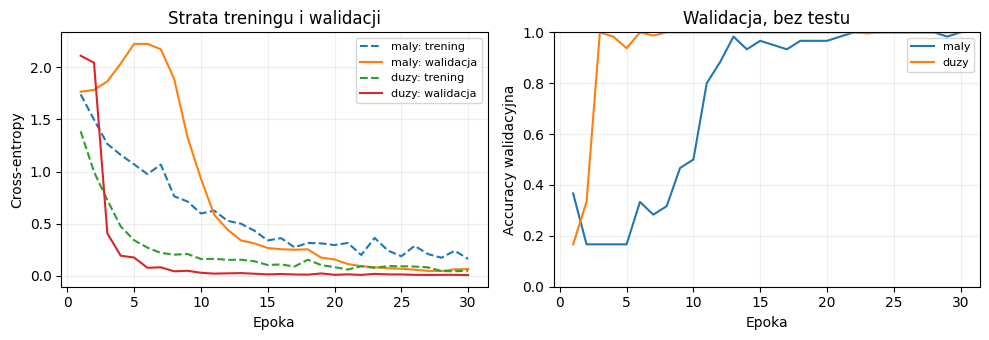

In [5]:
models, histories = {}, {}
for size in ('maly', 'duzy'):
    models[size], histories[size] = train_cnn(size)
assert histories['maly']['config']['initial_hash'] == histories['duzy']['config']['initial_hash']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for size, info in histories.items():
    epochs = [r['epoch'] for r in info['history']]
    axes[0].plot(epochs, [r['train_loss'] for r in info['history']], '--', label=f'{size}: trening')
    axes[0].plot(epochs, [r['val_loss'] for r in info['history']], label=f'{size}: walidacja')
    axes[1].plot(epochs, [r['val_accuracy'] for r in info['history']], label=size)
axes[0].set(xlabel='Epoka', ylabel='Cross-entropy', title='Strata treningu i walidacji')
axes[1].set(xlabel='Epoka', ylabel='Accuracy walidacyjna', ylim=(0, 1), title='Walidacja, bez testu')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'trening.png', dpi=170, bbox_inches='tight')
plt.show()

## C. S2k: pełne współczynniki trzech poziomów

Liczymy `wavedec2` dla Haar i db2 na oryginalnych obrazach 576 × 576, w skali [0, 1]. Tryb `periodization` i rozmiar podzielny przez 8 dają pasma: poziom 1 - 288 × 288, poziom 2 - 144 × 144, poziom 3 - 72 × 72. Na każdym poziomie rozkładamy ponownie tylko aproksymację.

S2 to **podpisane współczynniki**, a nie znormalizowane obrazki do wyświetlania. Zachowujemy A3 oraz H,V,D z poziomów 1-3. Pliki `.npy` mają układ (960, 576, 576), z pasmami spakowanymi przez `coeffs_to_array`. Tryb memory map nie wymaga trzymania całego S2 w RAM. Dwa zbiory zajmują około 2,4 GiB. Metadane zawierają kolejność obrazów, sposób odtworzenia i indeksy małego S1.

## D. S3k: dziewięć średnich energii detali

Z każdej pary (poziom, kierunek) tworzymy jedną cechę **mean(c²)**. Kolejność: **H1, V1, D1, H2, V2, D2, H3, V3, D3**. `wavedec2` zwraca detale w odwrotnej kolejności poziomów (3,2,1), dlatego jawnie je odwracamy. Aproksymacja nie wchodzi do wektora.

Kontrole: dokładnie 9 cech, nieujemność i skończoność; szczegóły stałego obrazu mają zerową energię; sygnał o średniej zero może mieć dodatnią energię; rekonstrukcja S2 odtwarza obraz; dla ortogonalnych falek i periodization suma kwadratów wszystkich współczynników zachowuje energię obrazu. Sama suma **średnich** energii pasm nie jest całkowitą energią, bo pasma mają różne liczby współczynników.

In [6]:
FEATURE_NAMES = [f'{band}{level}' for level in (1, 2, 3) for band in ('H', 'V', 'D')]


def detail_energy9(coeffs):
    assert len(coeffs) == 4
    return np.array([np.mean(np.square(band.astype(np.float64)))
                     for details in reversed(coeffs[1:]) for band in details], dtype=np.float64)


def load_original(i):
    with Image.open(records[int(i)]['path']) as image:
        return np.asarray(image, dtype=np.float32) / 255.0


for wavelet in WAVELETS:
    constant = pywt.wavedec2(np.ones((64, 64)), wavelet, mode=DWT_MODE, level=LEVELS)
    assert np.max(np.abs(detail_energy9(constant))) < 1e-24
zero_mean = np.array([-1.0, 1.0])
assert np.mean(zero_mean) == 0 and np.mean(zero_mean ** 2) == 1

features = {}
wavelet_checks = {}
for wavelet in WAVELETS:
    s2_file = OUT / 'S2' / f'S2_{wavelet}.npy'
    s3_file = OUT / f'S3_{wavelet}.npz'
    metadata_file = OUT / 'S2' / f'S2_{wavelet}_metadata.json'
    expected_metadata = {'data_signature': data_signature, 'wavelet': wavelet,
                         'level': LEVELS, 'mode': DWT_MODE, 'dtype': 'float32',
                         'shape': [len(records), 576, 576], 'filenames': filenames.tolist(),
                         'packing': 'pywt.coeffs_to_array; template from wavedec2(zeros((576,576)))',
                         'small_rows': sorted(np.concatenate(list(parts['maly'].values())).tolist()),
                         'feature_names': FEATURE_NAMES}
    use_cache = s2_file.exists() and s3_file.exists() and metadata_file.exists()
    if use_cache:
        assert json.loads(metadata_file.read_text(encoding='utf-8')) == expected_metadata
        with np.load(s3_file, allow_pickle=False) as saved:
            np.testing.assert_array_equal(saved['filenames'], filenames)
            features[wavelet] = saved['energy9'].copy()
        s2 = np.load(s2_file, mmap_mode='r')
        assert s2.shape == (len(records), 576, 576)
        print('Wczytano S2 i S3:', wavelet)
    else:
        s2 = np.lib.format.open_memmap(s2_file, mode='w+', dtype=np.float32,
                                      shape=(len(records), 576, 576))
        energy_rows = np.empty((len(records), 9), dtype=np.float64)
        for i in range(len(records)):
            image = load_original(i)
            coeffs = pywt.wavedec2(image, wavelet, mode=DWT_MODE, level=LEVELS)
            packed, _ = pywt.coeffs_to_array(coeffs)
            assert packed.shape == (576, 576)
            s2[i] = packed
            energy_rows[i] = detail_energy9(coeffs)
            if (i + 1) % 160 == 0:
                print(f'{wavelet}: zapisano {i + 1}/{len(records)} transformat.', flush=True)
        s2.flush()
        features[wavelet] = energy_rows
        np.savez_compressed(s3_file, energy9=energy_rows, labels=y, filenames=filenames,
                            feature_names=np.array(FEATURE_NAMES),
                            **{f'{size}_{split}': ids for size, splits in parts.items() for split, ids in splits.items()})
        save_json(metadata_file, expected_metadata)  # znacznik ukończenia dopiero po zapisaniu całości
    assert features[wavelet].shape == (len(records), 9)
    assert np.isfinite(features[wavelet]).all() and (features[wavelet] >= 0).all()
    # Odtwarzamy pierwszą transformację z dysku, nie z niezapisanego obiektu.
    template = pywt.wavedec2(np.zeros((576, 576), dtype=np.float32), wavelet, mode=DWT_MODE, level=LEVELS)
    _, slices = pywt.coeffs_to_array(template)
    saved_coeffs = pywt.array_to_coeffs(s2[0], slices, output_format='wavedec2')
    restored = pywt.waverec2(saved_coeffs, wavelet, mode=DWT_MODE)
    original = load_original(0)
    reconstruction_error = float(np.max(np.abs(restored - original)))
    original_energy = float(np.sum(original.astype(np.float64) ** 2))
    coefficient_energy = float(np.sum(s2[0].astype(np.float64) ** 2))
    relative_energy_error = abs(coefficient_energy - original_energy) / original_energy
    assert reconstruction_error < 2e-6 and relative_energy_error < 2e-6
    np.testing.assert_allclose(features[wavelet][0], detail_energy9(saved_coeffs), rtol=1e-7, atol=1e-12)
    wavelet_checks[wavelet] = {'max_reconstruction_error': reconstruction_error,
                              'relative_total_energy_error': relative_energy_error}
    print(wavelet, 'S3:', features[wavelet].shape, '| kontrole:', wavelet_checks[wavelet])
    del s2
save_json(OUT / 'kontrole_falek.json', wavelet_checks)

haar: zapisano 160/960 transformat.


haar: zapisano 320/960 transformat.


haar: zapisano 480/960 transformat.


haar: zapisano 640/960 transformat.


haar: zapisano 800/960 transformat.


...

db2: zapisano 480/960 transformat.


db2: zapisano 640/960 transformat.


db2: zapisano 800/960 transformat.


db2: zapisano 960/960 transformat.


db2 S3: (960, 9) | kontrole: {'max_reconstruction_error': 6.556510925292969e-07, 'relative_total_energy_error': 4.787148904994889e-08}


### Wizualizacja trzech poziomów i cech energii

W każdym panelu pasma pokazujemy oddzielnie. Dla detali stosujemy symetryczną skalę barw i podpisujemy średnią energię; kolor nie zastępuje wartości. A3 jest osobno, bez włączania do 9D. Do porównania energii między falami pokazujemy mediany po **dużym treningu**, bez etykiet i danych testowych do wyboru falek.

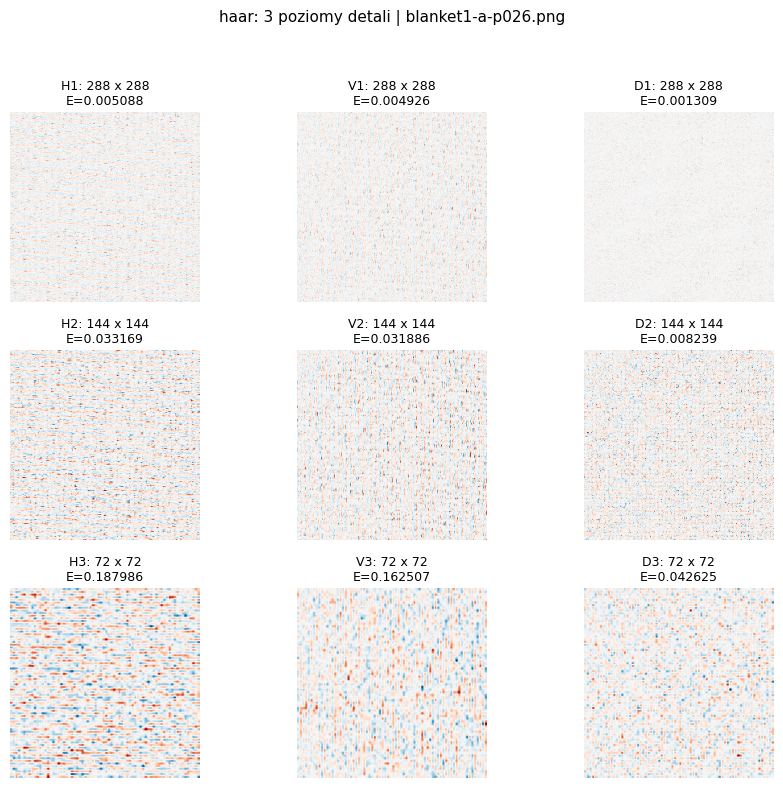

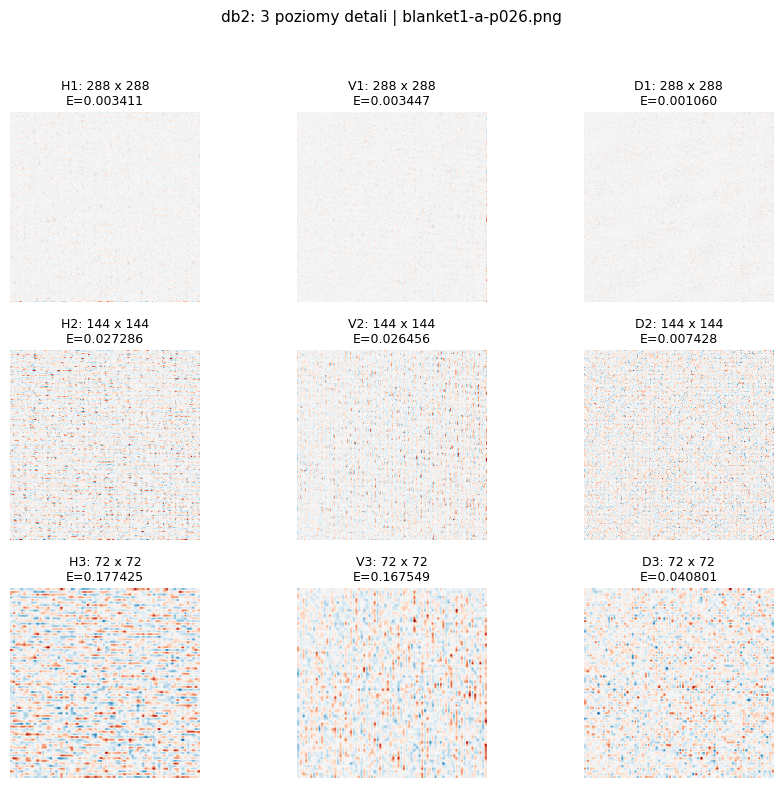

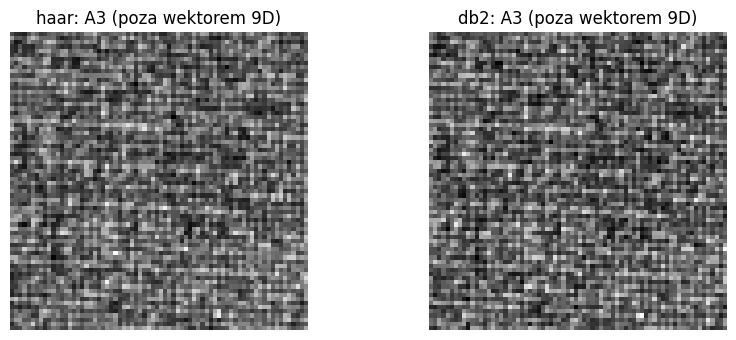

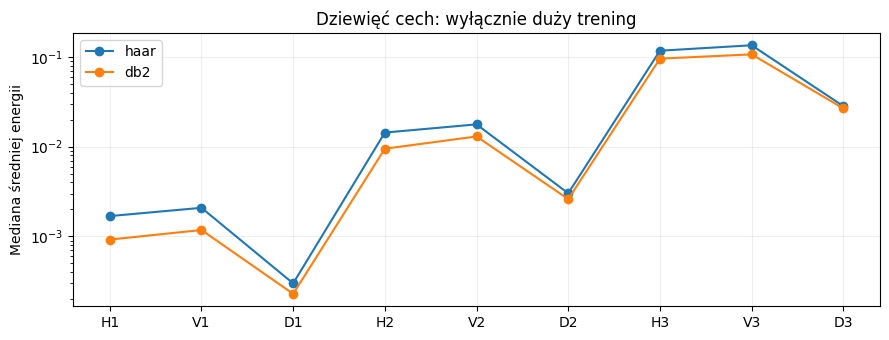

In [7]:
example_i = int(parts['duzy']['train'][0])
for wavelet in WAVELETS:
    coeffs = pywt.wavedec2(load_original(example_i), wavelet, mode=DWT_MODE, level=LEVELS)
    fig, axes = plt.subplots(3, 3, figsize=(9, 8))
    for row, details in enumerate(reversed(coeffs[1:])):
        for col, (name, band) in enumerate(zip(('H', 'V', 'D'), details)):
            vmax = max(float(np.max(np.abs(band))), 1e-12)
            axes[row, col].imshow(band, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
            energy = np.mean(band.astype(np.float64) ** 2)
            axes[row, col].set_title(f'{name}{row + 1}: {band.shape[0]} x {band.shape[1]}\nE={energy:.6f}', fontsize=9)
            axes[row, col].axis('off')
    fig.suptitle(f'{wavelet}: 3 poziomy detali | {filenames[example_i]}', fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(OUT / f'detale_{wavelet}.png', dpi=150, bbox_inches='tight')
    plt.show()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, wavelet in zip(axes, WAVELETS):
    coeffs = pywt.wavedec2(load_original(example_i), wavelet, mode=DWT_MODE, level=LEVELS)
    ax.imshow(coeffs[0], cmap='gray')
    ax.set_title(f'{wavelet}: A3 (poza wektorem 9D)')
    ax.axis('off')
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(9, 3.5))
for wavelet in WAVELETS:
    median = np.median(features[wavelet][parts['duzy']['train']], axis=0)
    ax.plot(FEATURE_NAMES, median, marker='o', label=wavelet)
ax.set(yscale='log', ylabel='Mediana średniej energii', title='Dziewięć cech: wyłącznie duży trening')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'energie9D.png', dpi=170, bbox_inches='tight')
plt.show()

## Ocena CNN i pomocnicza kontrola przydatności 9D

Obowiązkowym wynikiem D są wektory 9D. Dodatkowo uczymy na nich prosty klasyfikator liniowy: `log1p(energia) -> StandardScaler -> LogisticRegression(C=1)`. Standaryzacja dopasowuje się **wyłącznie do treningu** danego wariantu. Nie dobieramy C ani falki na teście. To kontrola użyteczności cech, a nie wymagane przez zadanie uczenie CNN na współczynnikach S2.

Test główny jest wspólny dla wszystkich modeli: 240 obrazów (40/klasę, źródło d). Osobno zapisujemy wspólne 60 z małego S1. Nie porównujemy procentów uzyskanych na różnych obrazach. CNN widzi pomniejszone obrazy, a 9D opisuje pełne 576 × 576 - ogranicza to interpretowanie różnicy jako wyłącznie wpływu architektury.

| Model | Trening N | Wspólny test N | Accuracy | F1-macro | Test 60: accuracy |
|---|---:|---:|---:|---:|---:|
| CNN_maly | 120 | 240 | 97.08% | 0.9706 | 96.67% |
| CNN_duzy | 480 | 240 | 100.00% | 1.0000 | 100.00% |
| 9D_haar_maly | 120 | 240 | 93.33% | 0.9307 | 91.67% |
| 9D_haar_duzy | 480 | 240 | 95.00% | 0.9484 | 93.33% |
| 9D_db2_maly | 120 | 240 | 90.00% | 0.8930 | 90.00% |
| 9D_db2_duzy | 480 | 240 | 89.58% | 0.8836 | 88.33% |

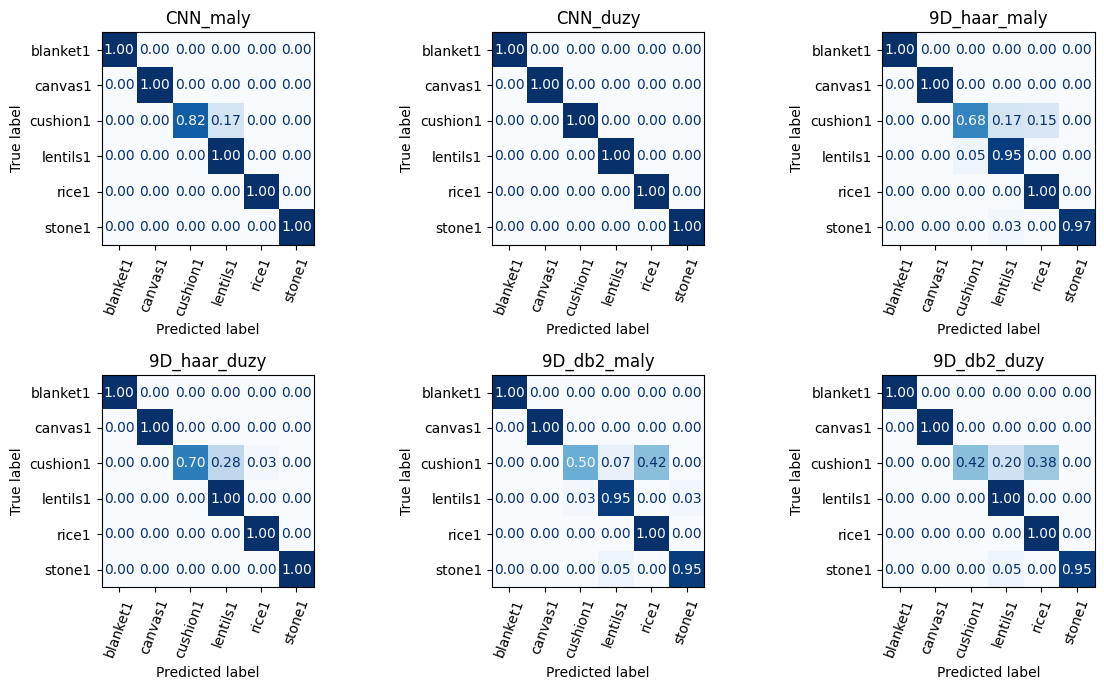

In [8]:
common_test = parts['duzy']['test']
small_test = parts['maly']['test']
evaluation_rows, predictions = [], {}
for size in ('maly', 'duzy'):
    metrics, preds = cnn_evaluate(models[size], common_test)
    small_metrics, _ = cnn_evaluate(models[size], small_test)
    name = f'CNN_{size}'
    predictions[name] = preds
    evaluation_rows.append({'model': name, 'train_n': len(parts[size]['train']),
                            'test_n': len(common_test), 'accuracy': metrics['accuracy'],
                            'f1_macro': metrics['f1_macro'], 'small_test_accuracy': small_metrics['accuracy']})
for wavelet in WAVELETS:
    transformed = np.log1p(features[wavelet])
    for size in ('maly', 'duzy'):
        train_ids = parts[size]['train']
        classifier = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000, random_state=SEED))
        classifier.fit(transformed[train_ids], y[train_ids])
        preds = classifier.predict(transformed[common_test])
        small_preds = classifier.predict(transformed[small_test])
        name = f'9D_{wavelet}_{size}'
        predictions[name] = preds
        evaluation_rows.append({'model': name, 'train_n': len(train_ids), 'test_n': len(common_test),
                                'accuracy': float(accuracy_score(y[common_test], preds)),
                                'f1_macro': float(f1_score(y[common_test], preds, labels=np.arange(len(CLASSES)),
                                                          average='macro', zero_division=0)),
                                'small_test_accuracy': float(accuracy_score(y[small_test], small_preds))})
table = ['| Model | Trening N | Wspólny test N | Accuracy | F1-macro | Test 60: accuracy |',
         '|---|---:|---:|---:|---:|---:|']
for row in evaluation_rows:
    table.append(f'| {row["model"]} | {row["train_n"]} | {row["test_n"]} | '
                 f'{100*row["accuracy"]:.2f}% | {row["f1_macro"]:.4f} | {100*row["small_test_accuracy"]:.2f}% |')
display(Markdown('\n'.join(table)))
with (OUT / 'wyniki.csv').open('w', newline='', encoding='utf-8') as output:
    writer = csv.DictWriter(output, fieldnames=list(evaluation_rows[0]))
    writer.writeheader()
    writer.writerows(evaluation_rows)
np.savez_compressed(OUT / 'predykcje.npz', y_true=y[common_test], test_rows=common_test, **predictions)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, preds) in zip(axes.flat, predictions.items()):
    matrix = confusion_matrix(y[common_test], preds, labels=np.arange(len(CLASSES)), normalize='true')
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False,
                                                               xticks_rotation=70, values_format='.2f')
    ax.set_title(name)
fig.tight_layout()
fig.savefig(OUT / 'macierze_pomylek.png', dpi=170, bbox_inches='tight')
plt.show()

### Odczyt wykresów i macierzy pomyłek

Na pokazanym przykładzie `blanket1-a-p026` drobne detale poziomu 1 przechodzą w bardziej czytelny, regularny układ na poziomie 3. Wykres median energii treningowych ma największe H3 i V3, a niższe energie diagonalne. **Nie oznacza to, że poziom 3 jest najlepszą reprezentacją:** pasma mają inną skalę i liczbę współczynników, a ich energia nie mierzy rozdzielania klas. Klasyfikator 9D używa wszystkich poziomów łącznie; nie przeprowadzono osobnego porównania klasyfikatorów dla każdego poziomu. Każdy panel detali ma własną skalę barw, więc nasycenia kolorów nie porównujemy bezpośrednio.

Macierze pokazują konkretne źródło różnicy: mała CNN popełnia 7 błędów, wszystkie `cushion1` → `lentils1`; duża CNN rozpoznaje wszystkie 240 obrazów tego testu. Dla dużego 9D/Haar klasa `cushion1` ma 28/40 poprawnych odpowiedzi, a dla 9D/db2 17/40. Zatem różnica nie dotyczy jednakowo wszystkich klas - descriptor db2 szczególnie gorzej rozdziela `cushion1` od `rice1` i `lentils1`. Utrata układu przestrzennego przez redukcję do energii może być jednym z powodów, ale sam ten eksperyment nie rozstrzyga przyczyny.

**100%** dotyczy tylko wybranych 6 klas, jednej fotografii testowej na klasę i jednego ziarna. Nie jest wynikiem dla wszystkich 28 klas ani dowodem odporności na inne warunki fotografowania.

## Wnioski liczbowe i granice interpretacji

Nie uznajemy ostatniego poziomu dekompozycji ani najładniejszej wizualizacji automatycznie za najlepszą reprezentację. Poziomy opisują różne skale. Energia usuwa znak i położenie szczegółów; dwa obrazy o tych samych dziewięciu energiach mogą mieć inny układ tekstury. Poniżej wnioski odnoszą się do rzeczywiście obliczonych wyników, a nie do wyglądu skupisk.

In [9]:
lookup = {r['model']: r for r in evaluation_rows}
cnn_delta = 100 * (lookup['CNN_duzy']['accuracy'] - lookup['CNN_maly']['accuracy'])
best_row = max(evaluation_rows, key=lambda r: r['accuracy'])
uniform_chance = 1 / len(CLASSES)
lines = [
    f'- Zwiększenie treningu ze 120 do 480 obrazów wiązało się ze zmianą accuracy CNN o **{cnn_delta:+.2f} p.p.** na tym samym teście 240. Walidacje różnią się rozmiarem, więc nie izolujemy wyłącznie wpływu liczby obrazów treningowych.',
    f'- Największą accuracy w tym przebiegu uzyskał **{best_row["model"]}: {100*best_row["accuracy"]:.2f}%**, F1-macro {best_row["f1_macro"]:.4f}. To opis jednego przebiegu, bez testu istotności.',
    f'- Przy 6 równolicznych klasach oczekiwana accuracy jednostajnego losowania wynosi **{100*uniform_chance:.2f}%** (nie 50%: problem nie jest binarny). Wszystkie porównania odnoszą się do konkretnego punktu odniesienia.',
]
for wavelet in WAVELETS:
    delta = 100 * (lookup[f'9D_{wavelet}_duzy']['accuracy'] - lookup[f'9D_{wavelet}_maly']['accuracy'])
    lines.append(f'- Dla 9D/{wavelet} większy trening zmienił accuracy o **{delta:+.2f} p.p.**; nie wybrano falki ani parametrów klasyfikatora na podstawie testu.')
display(Markdown('\n'.join(lines)))
experiment_summary = {'classes': CLASSES, 'seed': SEED, 'dataset_signature': data_signature,
                      'versions': versions, 'wavelets': list(WAVELETS), 'levels': LEVELS,
                      'energy_definition': 'mean(detail_coefficients ** 2); approximation excluded',
                      'feature_names': FEATURE_NAMES, 'group_split': 'a,b=train; c=validation; d=test',
                      'counts': {size: {split: len(ids) for split, ids in splits.items()} for size, splits in parts.items()},
                      'best_epochs': {size: info['best_epoch'] for size, info in histories.items()},
                      'wavelet_checks': wavelet_checks, 'results': evaluation_rows,
                      'cnn_delta_pp': cnn_delta, 'conclusions': lines,
                      'limitations': ['one fixed group split and seed', 'different validation counts',
                                      'CNN at 192x192 versus 9D at 576x576', 'no statistical significance test']}
save_json(OUT / 'podsumowanie.json', experiment_summary)
print('Zapisano metryki, predykcje, wagi, historie, podziały, S2, S3 i wykresy w:', OUT)

- Zwiększenie treningu ze 120 do 480 obrazów wiązało się ze zmianą accuracy CNN o **+2.92 p.p.** na tym samym teście 240. Walidacje różnią się rozmiarem, więc nie izolujemy wyłącznie wpływu liczby obrazów treningowych.
- Największą accuracy w tym przebiegu uzyskał **CNN_duzy: 100.00%**, F1-macro 1.0000. To opis jednego przebiegu, bez testu istotności.
- Przy 6 równolicznych klasach oczekiwana accuracy jednostajnego losowania wynosi **16.67%** (nie 50%: problem nie jest binarny). Wszystkie porównania odnoszą się do konkretnego punktu odniesienia.
- Dla 9D/haar większy trening zmienił accuracy o **+1.67 p.p.**; nie wybrano falki ani parametrów klasyfikatora na podstawie testu.
- Dla 9D/db2 większy trening zmienił accuracy o **-0.42 p.p.**; nie wybrano falki ani parametrów klasyfikatora na podstawie testu.

Zapisano metryki, predykcje, wagi, historie, podziały, S2, S3 i wykresy w: C:\Users\mateu\Desktop\Studia\MRO\lab4\wyniki_lab4


## Sprawdzenie wykonania A-E

- **A:** pełne dane 28 × 160; archiwa, manifest pobrań i kontrola 576 × 576.
- **B:** mały S1: 6 × 40, wytrenowana CNN, dropout i augmentacja.
- **C:** pełne S2 dla Haar i db2, po trzy poziomy, współczynniki ze znakiem i zapis do pliku.
- **D:** S3 dla obu falek i rozmiarów; dokładnie 9 średnich energii detali, bez aproksymacji.
- **E:** duży S1: te same 6 klas × 160, osobna CNN; wspólny test do porównania. S2/S3 dla dużego S1 nie są duplikowane dla małego - mapowanie zapisano w metadanych i `podzialy.npz`.

Przy implementacji użyto Codex. Odpowiedzi sprawdzono kontrolą podziału po fotografii źródłowej, rekonstrukcją falkową, kontrolą energii i wymiaru 9D, odtworzeniem zapisanych wag i metrykami z predykcji testowych. Sam wykres energii nie potwierdza lepszej klasyfikacji; do tego służą wyniki na wspólnym teście.